In [1]:
from numpy import unique
from numpy import where
from matplotlib import pyplot
from sklearn.datasets import make_classification
from sklearn.cluster import KMeans

In [2]:
# initialize the data set we'll work with
training_data, _ = make_classification(
    n_samples=1000,
    n_features=2,
    n_informative=2,
    n_redundant=0,
    n_clusters_per_class=1,
    random_state=4
)

In [3]:
# define the model
kmeans_model = KMeans(n_clusters=8)

In [4]:
# assign each data point to a cluster
kmeans_result = kmeans_model.fit_predict(training_data)

In [5]:
kmeans_result

array([1, 2, 2, 2, 4, 0, 2, 1, 1, 1, 6, 7, 7, 0, 5, 0, 6, 7, 7, 0, 0, 1,
       3, 7, 4, 5, 2, 0, 2, 2, 2, 2, 1, 3, 0, 6, 6, 0, 6, 5, 6, 7, 7, 5,
       2, 1, 0, 1, 6, 0, 1, 7, 1, 7, 1, 1, 4, 2, 2, 2, 6, 0, 2, 1, 7, 2,
       3, 7, 5, 2, 1, 0, 0, 0, 4, 2, 5, 3, 5, 2, 6, 6, 0, 2, 1, 3, 4, 7,
       0, 2, 7, 5, 3, 0, 1, 1, 7, 7, 0, 2, 5, 2, 1, 5, 0, 4, 7, 0, 1, 3,
       3, 0, 7, 0, 1, 0, 0, 0, 0, 2, 5, 4, 4, 7, 4, 2, 6, 4, 7, 3, 2, 2,
       2, 2, 5, 0, 0, 2, 6, 0, 3, 1, 1, 7, 7, 0, 7, 3, 4, 1, 1, 1, 2, 5,
       1, 1, 6, 1, 3, 1, 3, 1, 5, 1, 2, 4, 1, 7, 4, 2, 1, 6, 2, 6, 4, 1,
       6, 5, 0, 7, 1, 1, 2, 1, 2, 3, 4, 1, 6, 1, 2, 7, 0, 0, 7, 5, 0, 2,
       2, 2, 1, 3, 6, 7, 1, 5, 0, 6, 1, 7, 7, 3, 0, 2, 1, 3, 1, 1, 3, 5,
       2, 5, 2, 4, 7, 5, 5, 2, 2, 7, 3, 5, 7, 1, 7, 1, 1, 7, 2, 5, 7, 7,
       3, 1, 4, 0, 5, 4, 1, 6, 0, 1, 0, 4, 5, 6, 7, 7, 7, 6, 6, 6, 7, 1,
       7, 0, 2, 3, 0, 7, 1, 7, 1, 0, 5, 2, 0, 7, 2, 1, 7, 7, 7, 7, 1, 1,
       4, 2, 1, 6, 7, 7, 2, 2, 7, 7, 1, 2, 5, 4, 7,

In [6]:
# get all of the unique clusters
kmeans_clusters = unique(kmeans_result)
kmeans_clusters

array([0, 1, 2, 3, 4, 5, 6, 7], dtype=int32)

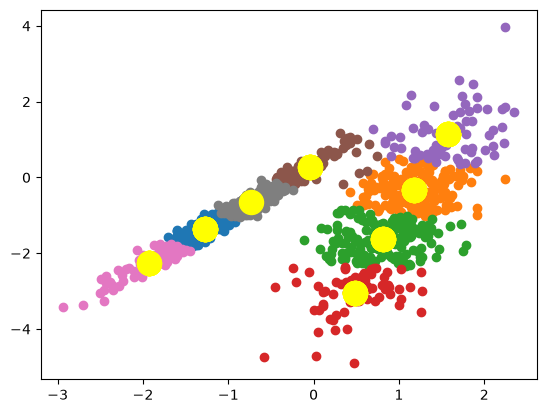

In [7]:
for kmean_clusters in kmeans_clusters:
    # get data points that fall in this cluster
    index = where(kmeans_result == kmean_clusters)
    # make the plot
    pyplot.scatter(training_data[index, 0], training_data[index, 1],)
    pyplot.scatter(kmeans_model.cluster_centers_[:, 0], kmeans_model.cluster_centers_[:, 1], s=300, c='yellow', label='Centroids')

pyplot.show()

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

## Data Exploration

In [9]:
DATASET_PATH = 'Mall_Customers.csv'

In [10]:
df = pd.read_csv(DATASET_PATH)
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


## Prepare Features

In [12]:
X = df.iloc[:, [3, 4]].values
X

array([[ 15,  39],
       [ 15,  81],
       [ 16,   6],
       [ 16,  77],
       [ 17,  40],
       [ 17,  76],
       [ 18,   6],
       [ 18,  94],
       [ 19,   3],
       [ 19,  72],
       [ 19,  14],
       [ 19,  99],
       [ 20,  15],
       [ 20,  77],
       [ 20,  13],
       [ 20,  79],
       [ 21,  35],
       [ 21,  66],
       [ 23,  29],
       [ 23,  98],
       [ 24,  35],
       [ 24,  73],
       [ 25,   5],
       [ 25,  73],
       [ 28,  14],
       [ 28,  82],
       [ 28,  32],
       [ 28,  61],
       [ 29,  31],
       [ 29,  87],
       [ 30,   4],
       [ 30,  73],
       [ 33,   4],
       [ 33,  92],
       [ 33,  14],
       [ 33,  81],
       [ 34,  17],
       [ 34,  73],
       [ 37,  26],
       [ 37,  75],
       [ 38,  35],
       [ 38,  92],
       [ 39,  36],
       [ 39,  61],
       [ 39,  28],
       [ 39,  65],
       [ 40,  55],
       [ 40,  47],
       [ 40,  42],
       [ 40,  42],
       [ 42,  52],
       [ 42,  60],
       [ 43,

## Finding optimial number of clusters (Using Elbow Method)

In [13]:
wcss = [] # wcss - within-cluster sums of squares
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42)
    kmeans.fit(X)
    print("Number of clusters:", i)
    print("WCSS:", kmeans.inertia_)
    wcss.append(kmeans.inertia_)

Number of clusters: 1
WCSS: 269981.28
Number of clusters: 2
WCSS: 183653.32894736837
Number of clusters: 3
WCSS: 106348.37306211118
Number of clusters: 4
WCSS: 73880.64496247197
Number of clusters: 5
WCSS: 44448.45544793371
Number of clusters: 6
WCSS: 40825.16946386946
Number of clusters: 7
WCSS: 33642.579220779226
Number of clusters: 8
WCSS: 26686.83778518779
Number of clusters: 9
WCSS: 24766.47160979344
Number of clusters: 10
WCSS: 23103.122085983916


* n_clusters -  default=8
The number of clusters to form as well as the number of centroids to generate.

* init{‘k-means++’, ‘random’}, callable or array-like of shape (n_clusters, n_features), default=’k-means++’


Method for initialization:

‘k-means++’ : selects initial cluster centroids using sampling based on an empirical probability distribution of the points’ contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is “greedy k-means++”. It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.

‘random’: choose n_clusters observations (rows) at random from data for the initial centroids.

If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.

If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.

* n_init‘auto’ or int, default=’auto’
Number of times the k-means algorithm is run with different centroid seeds. The final results is the best output of n_init consecutive runs in terms of inertia. Several runs are recommended for sparse high-dimensional problems

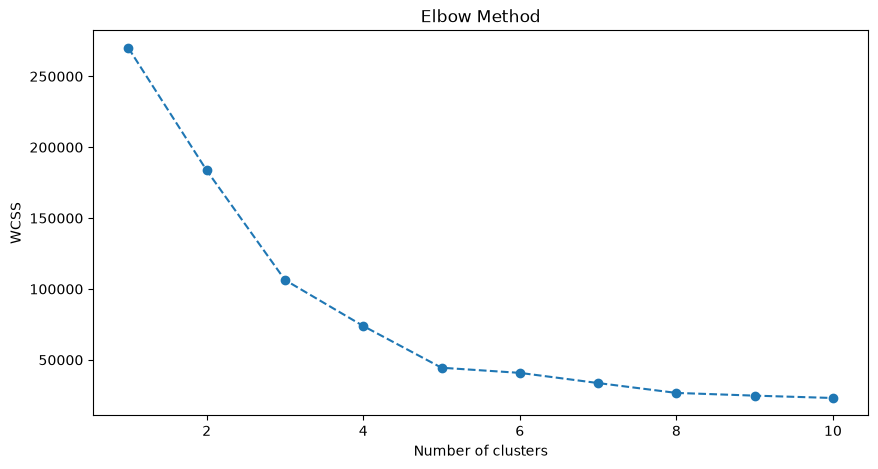

In [14]:
# Plotting the Elbow method
plt.figure(figsize=(10,5))
plt.plot(range(1, 11), wcss, marker='o', linestyle='--')
plt.title('Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('WCSS')  # Within Cluster Sum of Squares
plt.show()

## Train the model

In [15]:
kmeans = KMeans(n_clusters=5, init='k-means++', random_state=42)
y_kmeans = kmeans.fit_predict(X)

## Visualise the clusters

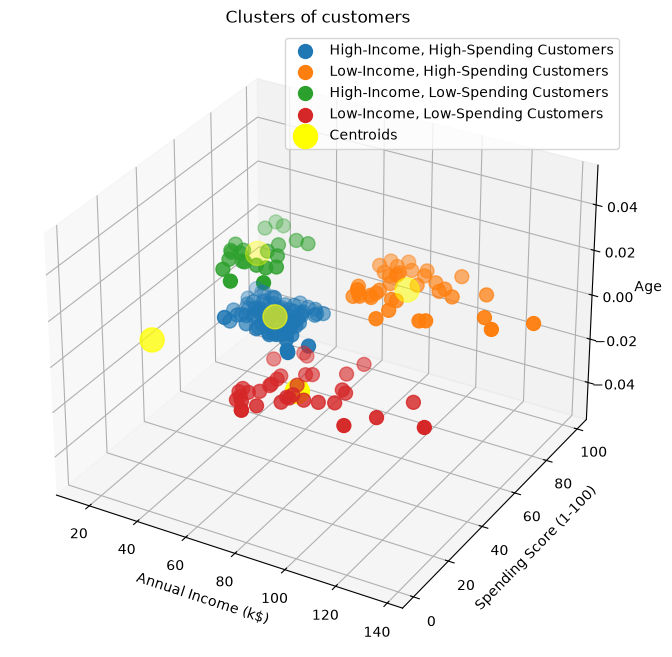

In [16]:
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

# Renamed cluster labels
cluster_labels = ['High-Income, High-Spending Customers',
                  'Low-Income, High-Spending Customers',
                  'High-Income, Low-Spending Customers',
                  'Low-Income, Low-Spending Customers']

# Plotting data points and centroids with renamed clusters
for i in range(4):  # Iterate up to 4, not 5
    ax.scatter(X[y_kmeans == i, 0], X[y_kmeans == i, 1], s=100, label=cluster_labels[i])

ax.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], s=300, c='yellow', label='Centroids')

ax.set_title('Clusters of customers')
ax.set_xlabel('Annual Income (k$)')
ax.set_ylabel('Spending Score (1-100)')
ax.set_zlabel('Age')
plt.legend()
plt.show()

## Predictions over new test data

In [17]:
# Generating dummy data
dummy_data = np.array([[50, 70],   # High-Income, High-Spending Customers
                       [20, 80],   # Low-Income, High-Spending Customers
                       [90, 20],   # High-Income, Low-Spending Customers
                       [30, 30],   # Low-Income, Low-Spending Customers
                       [70, 50]])  # Unknown data point

# Predicting clusters for dummy data
dummy_clusters = kmeans.predict(dummy_data)

# Renaming cluster labels for dummy data
dummy_cluster_labels = ['High-Income, High-Spending Customers',
                        'Low-Income, High-Spending Customers',
                        'High-Income, Low-Spending Customers',
                        'Low-Income, Low-Spending Customers',
                        'Unknown Data'
                        ]


# Printing predicted clusters for dummy data
for i in range(len(dummy_data)):
    print(f"Data point {i+1} belongs to: {dummy_cluster_labels[dummy_clusters[i]]}")

Data point 1 belongs to: High-Income, High-Spending Customers
Data point 2 belongs to: High-Income, Low-Spending Customers
Data point 3 belongs to: Low-Income, Low-Spending Customers
Data point 4 belongs to: Unknown Data
Data point 5 belongs to: High-Income, High-Spending Customers


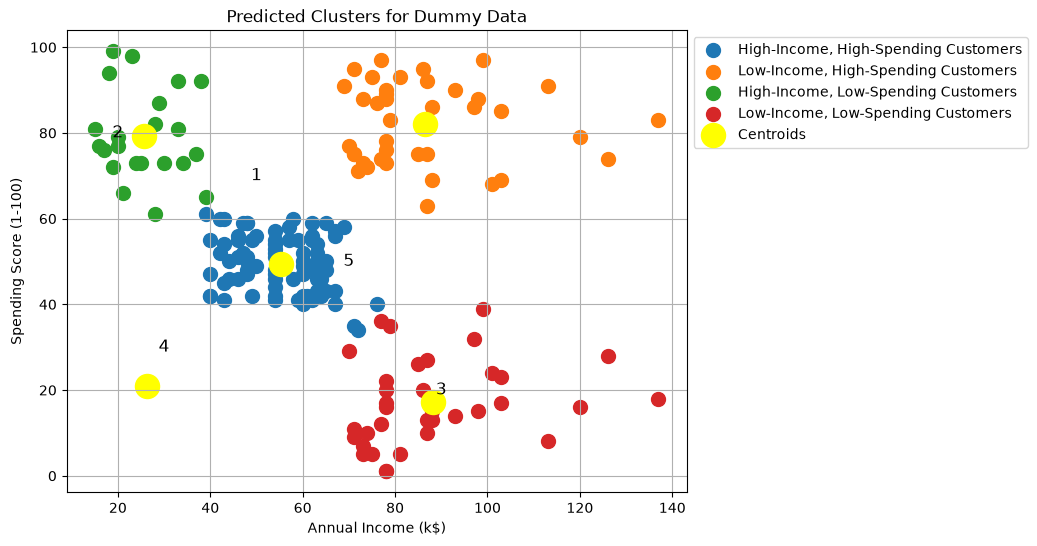

In [18]:
# Visualizing predicted clusters for dummy data
plt.figure(figsize=(8, 6))

# Plotting original clusters
for i in range(4):
    plt.scatter(X[y_kmeans == i, 0], X[y_kmeans == i, 1], s=100, label=dummy_cluster_labels[i])

# Plotting dummy data with predicted clusters and annotating data points with numbers
for i in range(len(dummy_data)):
    plt.scatter(dummy_data[i, 0], dummy_data[i, 1], s=100, marker='', color='black')
    plt.text(dummy_data[i, 0], dummy_data[i, 1], str(i+1), fontsize=12, ha='center', va='center')

plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], s=300, c='yellow', label='Centroids')

plt.title('Predicted Clusters for Dummy Data')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.grid(True)
plt.show()

In this analysis, we utilized K-Means clustering to segment customers based on their annual income and spending scores. Through visualization and interpretation of the clusters, we gained insights into customer behaviors and potential marketing strategies for different customer segments.

# Project 3

In [19]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt # for data visualization
import seaborn as sns # for statistical data visualization
%matplotlib inline

In [20]:
data = 'Live.csv'

df = pd.read_csv(data)

## Exploratory data analysis

In [21]:
df.head()

,status_id,status_type,status_published,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys,Column1,Column2,Column3,Column4
0,246675545449582_1649696485147474,video,4/22/2018 6:00,529,512,262,432,92,3,1,1,0,NaN,NaN,NaN,NaN
1,246675545449582_1649426988507757,photo,4/21/2018 22:45,150,0,0,150,0,0,0,0,0,NaN,NaN,NaN,NaN
2,246675545449582_1648730588577397,video,4/21/2018 6:17,227,236,57,204,21,1,1,0,0,NaN,NaN,NaN,NaN
3,246675545449582_1648576705259452,photo,4/21/2018 2:29,111,0,0,111,0,0,0,0,0,NaN,NaN,NaN,NaN
4,246675545449582_1645700502213739,photo,4/18/2018 3:22,213,0,0,204,9,0,0,0,0,NaN,NaN,NaN,NaN


In [22]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7050 entries, 0 to 7049
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   status_id         7050 non-null   str    
 1   status_type       7050 non-null   str    
 2   status_published  7050 non-null   str    
 3   num_reactions     7050 non-null   int64  
 4   num_comments      7050 non-null   int64  
 5   num_shares        7050 non-null   int64  
 6   num_likes         7050 non-null   int64  
 7   num_loves         7050 non-null   int64  
 8   num_wows          7050 non-null   int64  
 9   num_hahas         7050 non-null   int64  
 10  num_sads          7050 non-null   int64  
 11  num_angrys        7050 non-null   int64  
 12  Column1           0 non-null      float64
 13  Column2           0 non-null      float64
 14  Column3           0 non-null      float64
 15  Column4           0 non-null      float64
dtypes: float64(4), int64(9), str(3)
memory usage: 881.4 K

In [23]:
df.isnull().sum()

status_id              0
status_type            0
status_published       0
num_reactions          0
num_comments           0
num_shares             0
num_likes              0
num_loves              0
num_wows               0
num_hahas              0
num_sads               0
num_angrys             0
Column1             7050
Column2             7050
Column3             7050
Column4             7050
dtype: int64

We can see that there are 4 redundant columns in the dataset. We should drop them before proceeding further.



In [24]:
df.drop(['Column1', 'Column2', 'Column3', 'Column4'], axis=1, inplace=True)

In [25]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7050 entries, 0 to 7049
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   status_id         7050 non-null   str  
 1   status_type       7050 non-null   str  
 2   status_published  7050 non-null   str  
 3   num_reactions     7050 non-null   int64
 4   num_comments      7050 non-null   int64
 5   num_shares        7050 non-null   int64
 6   num_likes         7050 non-null   int64
 7   num_loves         7050 non-null   int64
 8   num_wows          7050 non-null   int64
 9   num_hahas         7050 non-null   int64
 10  num_sads          7050 non-null   int64
 11  num_angrys        7050 non-null   int64
dtypes: int64(9), str(3)
memory usage: 661.1 KB


We can see that, there are 3 character variables (data type = object) and remaining 9 numerical variables (data type = int64).

In [26]:
# view the labels in the variable

df['status_id'].unique()

<StringArray>
[ '246675545449582_1649696485147474',  '246675545449582_1649426988507757',
  '246675545449582_1648730588577397',  '246675545449582_1648576705259452',
  '246675545449582_1645700502213739',  '246675545449582_1645650162218773',
  '246675545449582_1645564175560705',  '246675545449582_1644824665634656',
  '246675545449582_1644655795651543',  '246675545449582_1638788379571618',
 ...
 '1050855161656896_1063071050435307', '1050855161656896_1062020473873698',
 '1050855161656896_1061944223881323', '1050855161656896_1061918183883927',
 '1050855161656896_1061906620551750', '1050855161656896_1061863470556065',
 '1050855161656896_1061334757275603', '1050855161656896_1060126464063099',
 '1050855161656896_1058663487542730', '1050855161656896_1050858841656528']
Length: 6997, dtype: str

In [27]:
# view how many different types of variables are there

len(df['status_id'].unique())

6997

In [28]:
 #view the labels in the variable

df['status_published'].unique()

<StringArray>
[ '4/22/2018 6:00', '4/21/2018 22:45',  '4/21/2018 6:17',  '4/21/2018 2:29',
  '4/18/2018 3:22',  '4/18/2018 2:14',  '4/18/2018 0:24',  '4/17/2018 7:42',
  '4/17/2018 3:33',  '4/11/2018 4:53',
 ...
 '9/25/2016 13:29',  '9/24/2016 8:15',  '9/24/2016 6:07',  '9/24/2016 5:07',
  '9/24/2016 4:37',  '9/24/2016 2:58', '9/23/2016 11:19', '9/21/2016 23:03',
  '9/20/2016 0:43', '9/10/2016 10:30']
Length: 6913, dtype: str

In [29]:
# view how many different types of variables are there

len(df['status_published'].unique())

6913

Again, we can see that there are 6913 unique labels in the status_published variable. The total number of instances in the dataset is 7050. So, it is also a approximately a unique identifier for each of the instances. Thus this is not a variable that we can use. Hence, I will drop it also.

In [30]:
# view the labels in the variable

df['status_type'].unique()

<StringArray>
['video', 'photo', 'link', 'status']
Length: 4, dtype: str

In [31]:
# view how many different types of variables are there

len(df['status_type'].unique())

4

We can see that there are 4 categories of labels in the status_type variable.



In [32]:
df.drop(['status_id', 'status_published'], axis=1, inplace=True)

In [33]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7050 entries, 0 to 7049
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   status_type    7050 non-null   str  
 1   num_reactions  7050 non-null   int64
 2   num_comments   7050 non-null   int64
 3   num_shares     7050 non-null   int64
 4   num_likes      7050 non-null   int64
 5   num_loves      7050 non-null   int64
 6   num_wows       7050 non-null   int64
 7   num_hahas      7050 non-null   int64
 8   num_sads       7050 non-null   int64
 9   num_angrys     7050 non-null   int64
dtypes: int64(9), str(1)
memory usage: 550.9 KB


In [34]:
df.head()

,status_type,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys
0,video,529,512,262,432,92,3,1,1,0
1,photo,150,0,0,150,0,0,0,0,0
2,video,227,236,57,204,21,1,1,0,0
3,photo,111,0,0,111,0,0,0,0,0
4,photo,213,0,0,204,9,0,0,0,0


We can see that there is 1 non-numeric column status_type in the dataset. I will convert it into integer equivalents.

In [35]:
X = df

y = df['status_type']

In [36]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

X['status_type'] = le.fit_transform(X['status_type'])

y = le.transform(y)

In [37]:
X.head()

,status_type,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys
0,3,529,512,262,432,92,3,1,1,0
1,1,150,0,0,150,0,0,0,0,0
2,3,227,236,57,204,21,1,1,0,0
3,1,111,0,0,111,0,0,0,0,0
4,1,213,0,0,204,9,0,0,0,0


In [38]:
cols = X.columns

In [39]:
from sklearn.preprocessing import MinMaxScaler

ms = MinMaxScaler()

X = ms.fit_transform(X)

In [40]:
X = pd.DataFrame(X, columns=[cols])

In [41]:
X.head()

,status_type,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys
0,1.000000,0.112314,0.024393,0.076519,0.091720,0.140030,0.010791,0.006369,0.019608,0.0
1,0.333333,0.031847,0.000000,0.000000,0.031847,0.000000,0.000000,0.000000,0.000000,0.0
2,1.000000,0.048195,0.011243,0.016647,0.043312,0.031963,0.003597,0.006369,0.000000,0.0
3,0.333333,0.023567,0.000000,0.000000,0.023567,0.000000,0.000000,0.000000,0.000000,0.0
4,0.333333,0.045223,0.000000,0.000000,0.043312,0.013699,0.000000,0.000000,0.000000,0.0


## K-Means model with two clusters

In [42]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=2, random_state=0)

kmeans.fit(X)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",2
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",0
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](2, 10)","[

In [43]:
kmeans.cluster_centers_

array([[9.54921576e-01, 6.46330441e-02, 2.67028654e-02, 2.93171709e-02,
        5.71231462e-02, 4.71007076e-02, 8.18581889e-03, 9.65207685e-03,
        8.04219428e-03, 7.19501847e-03],
       [3.28506857e-01, 3.90710874e-02, 7.54854864e-04, 7.53667113e-04,
        3.85438884e-02, 2.17448568e-03, 2.43721364e-03, 1.20039760e-03,
        2.75348016e-03, 1.45313276e-03]])

In [44]:
labels = kmeans.labels_

# check how many of the samples were correctly labeled
correct_labels = sum(y == labels)

print("Result: %d out of %d samples were correctly labeled." % (correct_labels, y.size))

Result: 4288 out of 7050 samples were correctly labeled.


In [45]:
print('Accuracy score: {0:0.2f}'. format(correct_labels/float(y.size)))

Accuracy score: 0.61


## Use elbow method to find optimal number of clusters

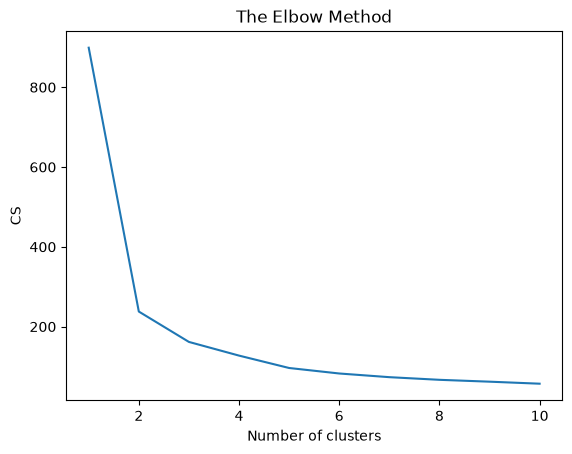

In [46]:
from sklearn.cluster import KMeans
cs = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters = i, init = 'k-means++', max_iter = 300, n_init = 10, random_state = 0)
    kmeans.fit(X)
    cs.append(kmeans.inertia_)
plt.plot(range(1, 11), cs)
plt.title('The Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('CS')
plt.show()

The kmeans.inertia_ attribute in scikit-learn is a measure of how well a k-means clustering model fits the data. It is calculated as the sum of the squared distances between each data point and its assigned cluster center.

A lower inertia_ score indicates a better fit, as it means that the data points are closer to their assigned cluster centers. Conversely, a higher inertia_ score indicates a worse fit.

* By the above plot, we can see that there is a kink at k=2.

* Hence k=2 can be considered a good number of the cluster to cluster this data.

* But, we have seen that I have achieved a weak classification accuracy of 1% with k=2.

* I will write the required code with k=2 again for convinience.

In [47]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=2,random_state=0)

kmeans.fit(X)

labels = kmeans.labels_

print(labels)

# check how many of the samples were correctly labeled

correct_labels = sum(y == labels)

print("Result: %d out of %d samples were correctly labeled." % (correct_labels, y.size))

print('Accuracy score: {0:0.2f}'. format(correct_labels/float(y.size)))

[0 1 0 ... 1 1 1]
Result: 4288 out of 7050 samples were correctly labeled.
Accuracy score: 0.61


So, our weak unsupervised classification model achieved a very weak classification accuracy of 61%.

let's check the model accuracy with different number of clusters.

## K-Means model with 3 clusters

In [48]:
kmeans = KMeans(n_clusters=3, random_state=0)

kmeans.fit(X)

# check how many of the samples were correctly labeled
labels = kmeans.labels_

correct_labels = sum(y == labels)
print("Result: %d out of %d samples were correctly labeled." % (correct_labels, y.size))
print('Accuracy score: {0:0.2f}'. format(correct_labels/float(y.size)))

Result: 4066 out of 7050 samples were correctly labeled.
Accuracy score: 0.58


## K-Means model with 4 clusters

In [49]:
kmeans = KMeans(n_clusters=4, random_state=0)

kmeans.fit(X)

# check how many of the samples were correctly labeled
labels = kmeans.labels_

correct_labels = sum(y == labels)
print("Result: %d out of %d samples were correctly labeled." % (correct_labels, y.size))
print('Accuracy score: {0:0.2f}'. format(correct_labels/float(y.size)))

Result: 4112 out of 7050 samples were correctly labeled.
Accuracy score: 0.58


We have achieved a relatively high accuracy of 62% with k=4.

In [50]:
kmeans = KMeans(n_clusters=5, random_state=0)

kmeans.fit(X)

# check how many of the samples were correctly labeled
labels = kmeans.labels_

correct_labels = sum(y == labels)
print("Result: %d out of %d samples were correctly labeled." % (correct_labels, y.size))
print('Accuracy score: {0:0.2f}'. format(correct_labels/float(y.size)))

Result: 4080 out of 7050 samples were correctly labeled.
Accuracy score: 0.58
